# Exploratory Data Analysis and Prediction of Netflix Movies and TV Shows


# Task 1: Data Understanding

### Step 1 — Import Libraries

# herry


In [1]:
# ── Standard Libraries ──────────────────────────────────────────
import pandas as pd
import numpy as np
import warnings
warnings.filterwarnings('ignore')

# ── Visualisation ────────────────────────────────────────────────
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

# ── Machine Learning ─────────────────────────────────────────────
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (
    mean_squared_error, mean_absolute_error, r2_score,
    accuracy_score, confusion_matrix, classification_report
)

# ── Plot Defaults ────────────────────────────────────────────────
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.labelsize'] = 12

print("All libraries imported successfully.")

All libraries imported successfully.


### Step 2 — Read Dataset

In [2]:
# Load the dataset — ensure netflix_titles.csv is in the same directory
df = pd.read_csv('netflix_titles.csv')

# Standardise column names: strip whitespace, lowercase
df.columns = df.columns.str.strip().str.lower().str.replace(' ', '_')

print(f"Dataset loaded successfully!")
print(f"Rows: {df.shape[0]}  |  Columns: {df.shape[1]}")
print()
print("First 5 rows:")
df.head()

Dataset loaded successfully!
Rows: 8807  |  Columns: 12

First 5 rows:


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


In [3]:
print("Last 5 rows:")
df.tail()

Last 5 rows:


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
8802,s8803,Movie,Zodiac,David Fincher,"Mark Ruffalo, Jake Gyllenhaal, Robert Downey J...",United States,"November 20, 2019",2007,R,158 min,"Cult Movies, Dramas, Thrillers","A political cartoonist, a crime reporter and a..."
8803,s8804,TV Show,Zombie Dumb,NaN,NaN,NaN,"July 1, 2019",2018,TV-Y7,2 Seasons,"Kids' TV, Korean TV Shows, TV Comedies","While living alone in a spooky town, a young g..."
8804,s8805,Movie,Zombieland,Ruben Fleischer,"Jesse Eisenberg, Woody Harrelson, Emma Stone, ...",United States,"November 1, 2019",2009,R,88 min,"Comedies, Horror Movies",Looking to survive in a world taken over by zo...
8805,s8806,Movie,Zoom,Peter Hewitt,"Tim Allen, Courteney Cox, Chevy Chase, Kate Ma...",United States,"January 11, 2020",2006,PG,88 min,"Children & Family Movies, Comedies","Dragged from civilian life, a former superhero..."
8806,s8807,Movie,Zubaan,Mozez Singh,"Vicky Kaushal, Sarah-Jane Dias, Raaghav Chanan...",India,"March 2, 2019",2015,TV-14,111 min,"Dramas, International Movies, Music & Musicals",A scrappy but poor boy worms his way into a ty...


### Step 3 — Dataset Shape, Describe, Info

In [4]:
# ── Shape ────────────────────────────────────────────────────────
print("SHAPE (rows, columns):", df.shape)
print("\nCOLUMNS:", df.columns.tolist())

SHAPE (rows, columns): (8807, 12)

COLUMNS: ['show_id', 'type', 'title', 'director', 'cast', 'country', 'date_added', 'release_year', 'rating', 'duration', 'listed_in', 'description']


In [5]:
# ── Describe ─────────────────────────────────────────────────────
print("DESCRIPTIVE STATISTICS (numerical):")
df.describe()

DESCRIPTIVE STATISTICS (numerical):


,release_year
count,8807.000000
mean,2014.180198
std,8.819312
min,1925.000000
25%,2013.000000
50%,2017.000000
75%,2019.000000
max,2021.000000


In [6]:
# ── Info ─────────────────────────────────────────────────────────
print("DATASET INFO:")
df.info()

DATASET INFO:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       8807 non-null   object
 1   type          8807 non-null   object
 2   title         8807 non-null   object
 3   director      6173 non-null   object
 4   cast          7982 non-null   object
 5   country       7976 non-null   object
 6   date_added    8797 non-null   object
 7   release_year  8807 non-null   int64 
 8   rating        8803 non-null   object
 9   duration      8804 non-null   object
 10  listed_in     8807 non-null   object
 11  description   8807 non-null   object
dtypes: int64(1), object(11)
memory usage: 825.8+ KB


In [7]:
# df.isna().sum()

In [8]:
# df.select_dtypes(exclude='number').columns

In [9]:
# df['director'].fillna('Missing')

In [10]:
# df.info()

In [11]:
# df['director'].value_counts(dropna=False)

In [12]:
# SimpleImputer(strategy='constant',fill_value='Missing')
# impute_dir=SimpleImputer(strategy='constant',fill_value='Missing')
# df['director']=impute_dir

In [13]:
# df.info()

In [14]:
# df['director'].value_counts(dropna=False)

In [15]:
# df.head(10)

In [16]:
def average_rating(ratings):
    total = sum(ratings)
    average = total / len(ratings)
print()

### Step 4 — Data Type Identification

In [17]:
print("DATA TYPES OF EACH COLUMN:")
print(df.dtypes)
print()
print("─" * 45)
print("QUANTITATIVE (Numerical) columns:")
num_cols_raw = df.select_dtypes(include=[np.number]).columns.tolist()
print(" ", num_cols_raw)

print("\nQUALITATIVE (Categorical / Object) columns:")
cat_cols_raw = df.select_dtypes(include=['object']).columns.tolist()
print(" ", cat_cols_raw)

DATA TYPES OF EACH COLUMN:
show_id         object
type            object
title           object
director        object
cast            object
country         object
date_added      object
release_year     int64
rating          object
duration        object
listed_in       object
description     object
dtype: object

─────────────────────────────────────────────
QUANTITATIVE (Numerical) columns:
  ['release_year']

QUALITATIVE (Categorical / Object) columns:
  ['show_id', 'type', 'title', 'director', 'cast', 'country', 'date_added', 'rating', 'duration', 'listed_in', 'description']


## Task 2: Exploratory Data Analysis (EDA)

> **Feature Engineering** — creating `duration_num`, `year_added`, and `content_age` before analysis.

In [18]:
# Extract numeric part from 'duration' (e.g., '90 min' → 90, '2 Seasons' → 2)
df['duration_num'] = df['duration'].str.extract(r'(\d+)').astype(float)

# Binary label: 1 = Movie, 0 = TV Show
df['is_movie'] = (df['type'] == 'Movie').astype(int)

# Year the title was added to Netflix
df['year_added'] = pd.to_datetime(df['date_added'], errors='coerce').dt.year

# Age of content when added (years between release and addition)
df['content_age'] = (df['year_added'] - df['release_year']).clip(lower=0)

print("✅ Features created: duration_num, is_movie, year_added, content_age")
df[['type','duration','duration_num','is_movie','year_added','content_age']].head(6)

✅ Features created: duration_num, is_movie, year_added, content_age


,type,duration,duration_num,is_movie,year_added,content_age
0,Movie,90 min,90.0,1,2021.0,1.0
1,TV Show,2 Seasons,2.0,0,2021.0,0.0
2,TV Show,1 Season,1.0,0,2021.0,0.0
3,TV Show,1 Season,1.0,0,2021.0,0.0
4,TV Show,2 Seasons,2.0,0,2021.0,0.0
5,TV Show,1 Season,1.0,0,2021.0,0.0


### Step 1 — Univariate Analysis (Histogram)

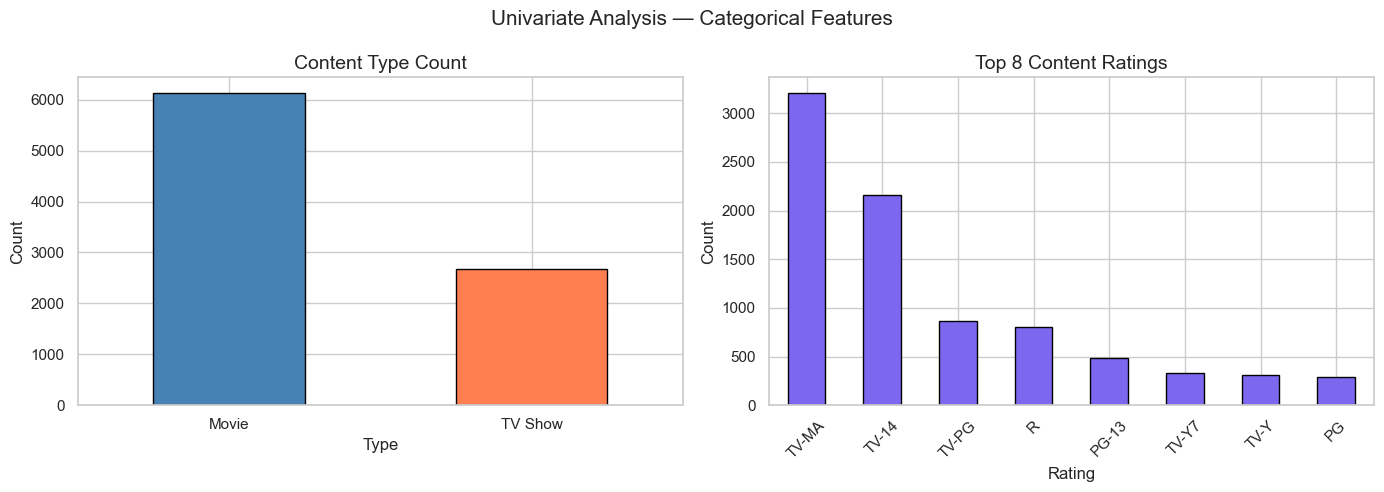

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Content Type (Bar)
df['type'].value_counts().plot(kind='bar', ax=axes[0],
                                color=['steelblue','coral'], edgecolor='black')
axes[0].set_title('Content Type Count')
axes[0].set_xlabel('Type')
axes[0].set_ylabel('Count')
axes[0].tick_params(axis='x', rotation=0)

# Top 8 Ratings
df['rating'].value_counts().head(8).plot(kind='bar', ax=axes[1],
                                          color='mediumslateblue', edgecolor='black')
axes[1].set_title('Top 8 Content Ratings')
axes[1].set_xlabel('Rating')
axes[1].set_ylabel('Count')
axes[1].tick_params(axis='x', rotation=45)

plt.suptitle('Univariate Analysis — Categorical Features', fontsize=15)
plt.tight_layout()
plt.show()

### Step 2 — Boxplot (Outlier Detection)

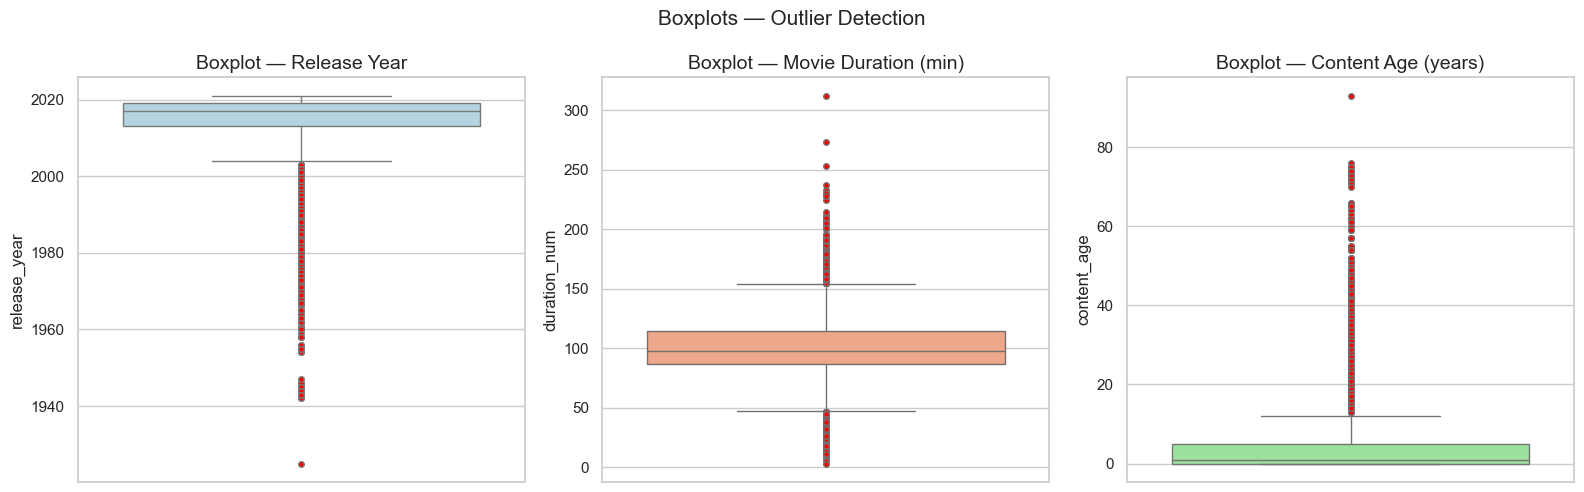

Red dots indicate outliers (values beyond 1.5 × IQR).


In [20]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# Release Year boxplot
sns.boxplot(y=df['release_year'], ax=axes[0], color='lightblue',
            flierprops=dict(marker='o', markerfacecolor='red', markersize=4))
axes[0].set_title('Boxplot — Release Year')

# Movie Duration boxplot
sns.boxplot(y=df[df['is_movie']==1]['duration_num'], ax=axes[1], color='lightsalmon',
            flierprops=dict(marker='o', markerfacecolor='red', markersize=4))
axes[1].set_title('Boxplot — Movie Duration (min)')

# Content Age boxplot
sns.boxplot(y=df['content_age'].dropna(), ax=axes[2], color='lightgreen',
            flierprops=dict(marker='o', markerfacecolor='red', markersize=4))
axes[2].set_title('Boxplot — Content Age (years)')

plt.suptitle('Boxplots — Outlier Detection', fontsize=15)
plt.tight_layout()
plt.show()

print("Red dots indicate outliers (values beyond 1.5 × IQR).")

### Step 3 — Bivariate Analysis 

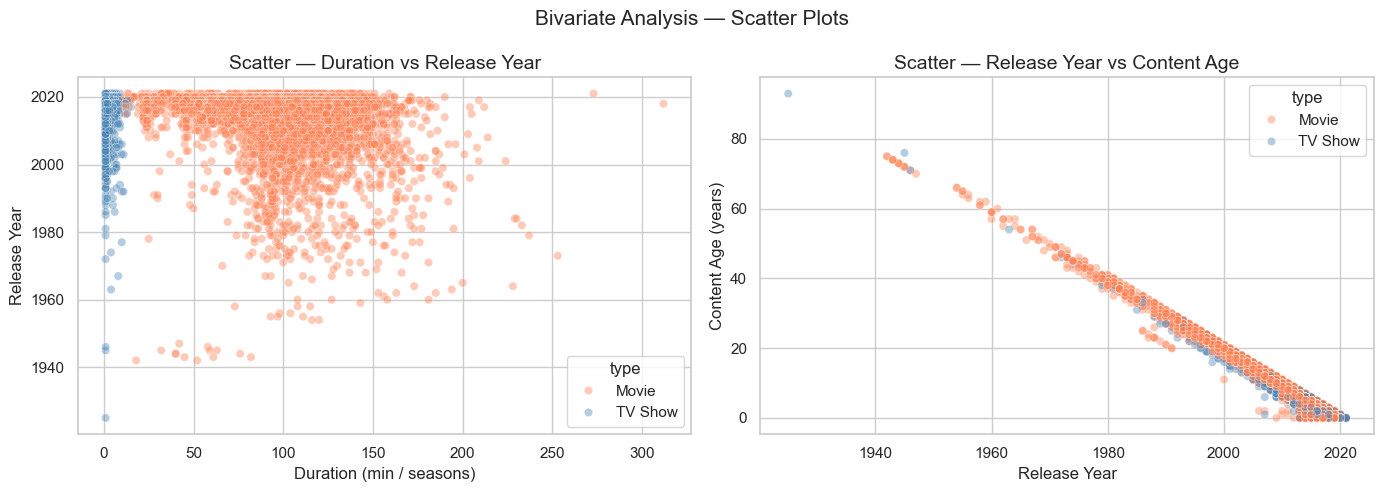

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Scatter: Duration vs Release Year
sns.scatterplot(x='duration_num', y='release_year', hue='type',
                data=df, alpha=0.4, ax=axes[0], palette={'Movie':'coral','TV Show':'steelblue'})
axes[0].set_title('Scatter — Duration vs Release Year')
axes[0].set_xlabel('Duration (min / seasons)')
axes[0].set_ylabel('Release Year')

# Scatter: Content Age vs Release Year
sns.scatterplot(x='release_year', y='content_age', hue='type',
                data=df.dropna(subset=['content_age']), alpha=0.4, ax=axes[1],
                palette={'Movie':'coral','TV Show':'steelblue'})
axes[1].set_title('Scatter — Release Year vs Content Age')
axes[1].set_xlabel('Release Year')
axes[1].set_ylabel('Content Age (years)')

plt.suptitle('Bivariate Analysis — Scatter Plots', fontsize=15)
plt.tight_layout()
plt.show()

In [15]:
print("Pearson Correlation between numerical features:")
print(df[['release_year','duration_num','content_age','is_movie']].corr(numeric_only=True).round(4))

Pearson Correlation between numerical features:
              release_year  duration_num  content_age  is_movie
release_year        1.0000       -0.2492      -0.9842   -0.1817
duration_num       -0.2492        1.0000       0.2588    0.8854
content_age        -0.9842        0.2588       1.0000    0.1816
is_movie           -0.1817        0.8854       0.1816    1.0000


### Step 4 — Multivariate Analysis (Bar, Heatmap, Pairplot)

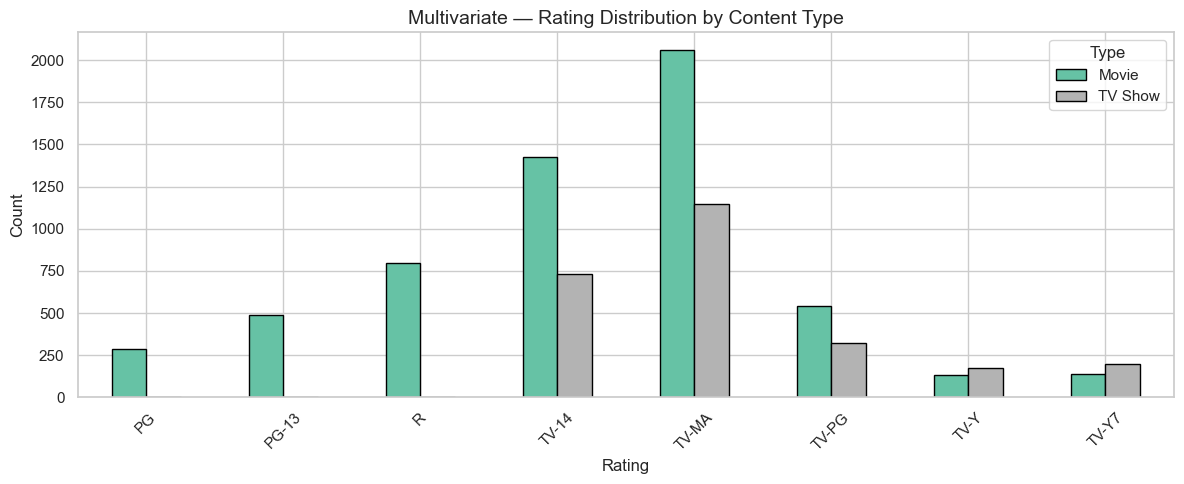

In [16]:
# ── Grouped Bar: Rating by Content Type ──────────────────────────
top_ratings = df['rating'].value_counts().head(8).index
rating_df   = df[df['rating'].isin(top_ratings)]
rating_type = rating_df.groupby(['rating','type']).size().unstack(fill_value=0)

fig, ax = plt.subplots(figsize=(12, 5))
rating_type.plot(kind='bar', ax=ax, edgecolor='black', colormap='Set2')
ax.set_title('Multivariate — Rating Distribution by Content Type')
ax.set_xlabel('Rating')
ax.set_ylabel('Count')
ax.tick_params(axis='x', rotation=45)
ax.legend(title='Type')
plt.tight_layout()
plt.show()

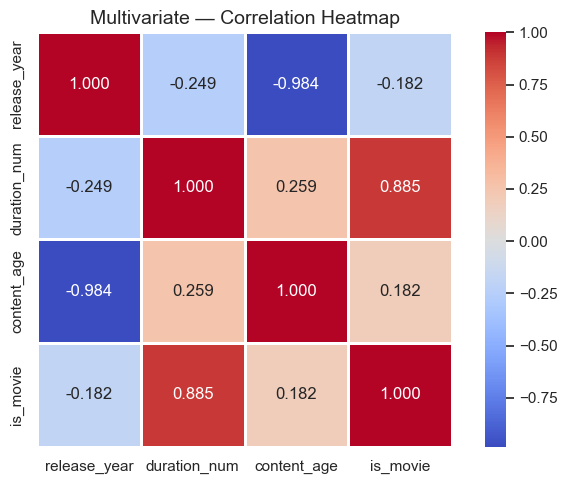

In [17]:
# ── Correlation Heatmap ───────────────────────────────────────────
corr = df[['release_year','duration_num','content_age','is_movie']].corr()

fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(corr, annot=True, fmt='.3f', cmap='coolwarm',
            linewidths=0.8, square=True, ax=ax)
ax.set_title('Multivariate — Correlation Heatmap')
plt.tight_layout()
plt.show()

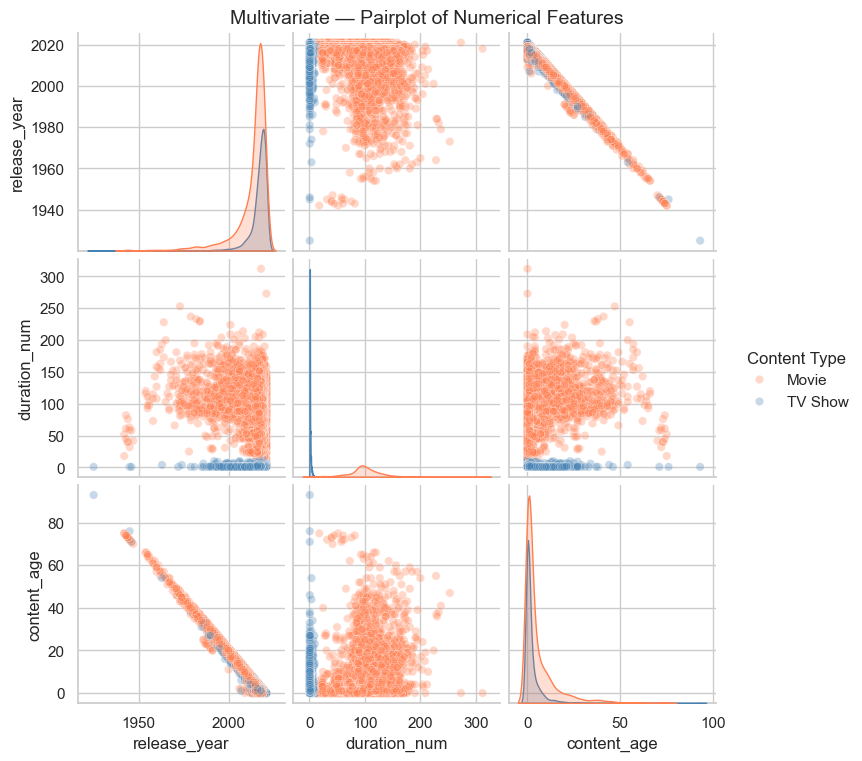

In [18]:
# ── Pairplot ──────────────────────────────────────────────────────
pair_df = df[['release_year','duration_num','content_age','is_movie']].dropna()
# Rename is_movie for readable legend
pair_df['Content Type'] = pair_df['is_movie'].map({1:'Movie', 0:'TV Show'})

sns.pairplot(pair_df.drop(columns='is_movie'), hue='Content Type',
             palette={'Movie':'coral','TV Show':'steelblue'},
             plot_kws={'alpha': 0.3}, diag_kind='kde')
plt.suptitle('Multivariate — Pairplot of Numerical Features', y=1.01, fontsize=14)
plt.show()

 Task 3: Handling Missing Values & Outliers


## Task 3: Handling Missing Values & Outliers

### Step 1 — Missing Values Check

Columns with missing values:


,Missing Count,Missing %
director,2634,29.91
country,831,9.44
cast,825,9.37
year_added,98,1.11
content_age,98,1.11
date_added,10,0.11
rating,4,0.05
duration,3,0.03
duration_num,3,0.03


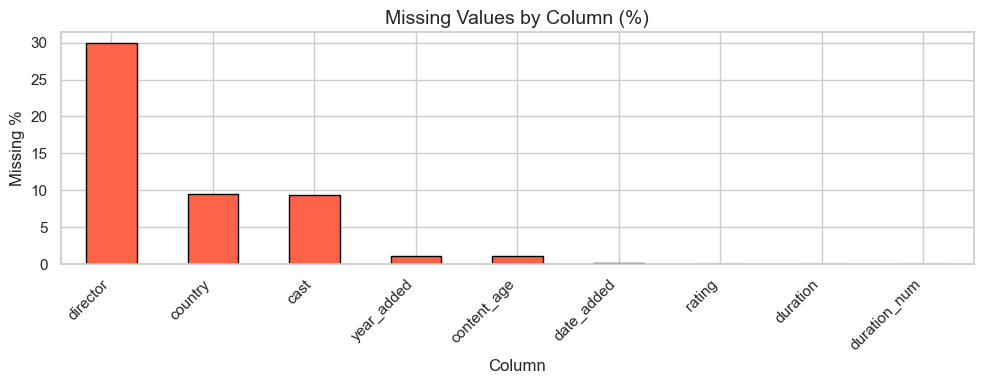

In [17]:
missing       = df.isnull().sum().sort_values(ascending=False)
missing_pct   = (missing / len(df) * 100).round(2)
missing_table = pd.DataFrame({'Missing Count': missing, 'Missing %': missing_pct})
missing_table = missing_table[missing_table['Missing Count'] > 0]

print("Columns with missing values:")
display(missing_table)

# Visual
fig, ax = plt.subplots(figsize=(10, 4))
missing_table['Missing %'].plot(kind='bar', ax=ax, color='tomato', edgecolor='black')
ax.set_title('Missing Values by Column (%)')
ax.set_ylabel('Missing %')
ax.set_xlabel('Column')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

### Step 2 — Fill Missing Values

In [19]:
# Fill categorical columns with "Unknown"
cat_cols = ['director', 'cast', 'country', 'rating']

for col in cat_cols:
    df[col].fillna("Unknown", inplace=True)

# Fill date_added
df['date_added'].fillna("Unknown", inplace=True)

# Drop rows where duration is missing (very few rows)
df.dropna(subset=['duration'], inplace=True)

In [20]:
df.isnull().sum()

show_id          0
type             0
title            0
director         0
cast             0
country          0
date_added       0
release_year     0
rating           0
duration         0
listed_in        0
description      0
duration_num     0
is_movie         0
year_added      98
content_age     98
dtype: int64

### Step 3 — Outlier Detection (IQR Method)

In [22]:
def detect_outliers_iqr(series: pd.Series) -> dict:
    """Return outlier count and bounds using the IQR method."""
    Q1  = series.quantile(0.25)
    Q3  = series.quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    outliers = series[(series < lower) | (series > upper)]
    return {
        'Q1': round(Q1, 2), 'Q3': round(Q3, 2), 'IQR': round(IQR, 2),
        'Lower Bound': round(lower, 2), 'Upper Bound': round(upper, 2),
        'Outlier Count': len(outliers)
    }

outlier_cols = ['release_year', 'duration_num', 'content_age']
outlier_summary = pd.DataFrame({col: detect_outliers_iqr(df[col].dropna())
                                 for col in outlier_cols}).T
print("Outlier Summary (IQR Method):")
display(outlier_summary)

Outlier Summary (IQR Method):


,Q1,Q3,IQR,Lower Bound,Upper Bound,Outlier Count
release_year,2013.0,2019.0,6.0,2004.0,2028.0,719.0
duration_num,2.0,106.0,104.0,-154.0,262.0,2.0
content_age,0.0,5.0,5.0,-7.5,12.5,966.0


✅ Outliers capped (Winsorisation) for: duration_num, content_age


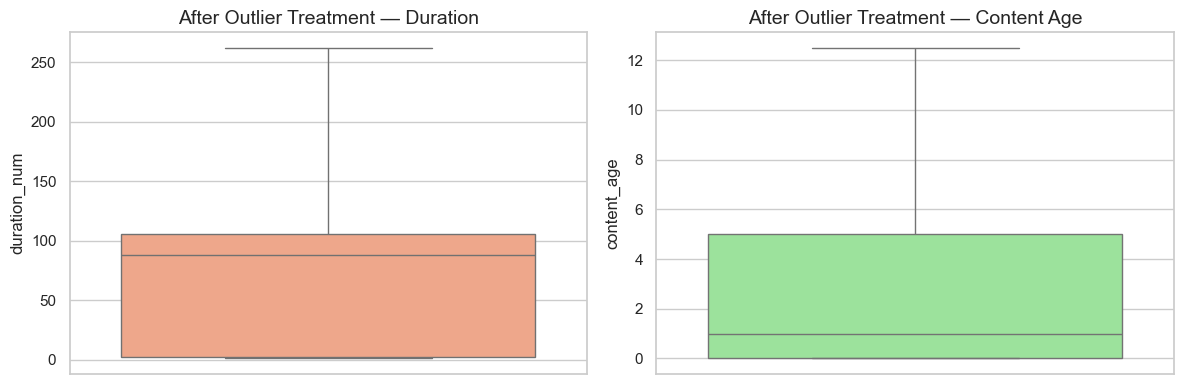

In [23]:
# Cap outliers using IQR (Winsorisation)
for col in ['duration_num', 'content_age']:
    Q1  = df[col].quantile(0.25)
    Q3  = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    df[col] = df[col].clip(lower=lower, upper=upper)

print("✅ Outliers capped (Winsorisation) for: duration_num, content_age")

# Post-treatment boxplots
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(y=df['duration_num'], ax=axes[0], color='lightsalmon')
axes[0].set_title('After Outlier Treatment — Duration')
sns.boxplot(y=df['content_age'].dropna(), ax=axes[1], color='lightgreen')
axes[1].set_title('After Outlier Treatment — Content Age')
plt.tight_layout()
plt.show()

## Task 4: Spread of Data

### Step 1 — Statistical Summary

In [25]:
num_cols = ['release_year', 'duration_num', 'content_age']

stats_dict = {}
for col in num_cols:
    s = df[col].dropna()
    stats_dict[col] = {
        'Count':    int(s.count()),
        'Mean':     round(s.mean(), 2),
        'Median':   round(s.median(), 2),
        'Mode':     round(s.mode()[0], 2),
        'Std Dev':  round(s.std(), 2),
        'Variance': round(s.var(), 2),
        'Min':      s.min(),
        'Max':      s.max(),
        'Range':    s.max() - s.min(),
        'Q1 (25%)': round(s.quantile(0.25), 2),
        'Q3 (75%)': round(s.quantile(0.75), 2),
        'IQR':      round(s.quantile(0.75) - s.quantile(0.25), 2),
    }

stats_df = pd.DataFrame(stats_dict).T
print("📊 Statistical Summary")
display(stats_df)

📊 Statistical Summary


,Count,Mean,Median,Mode,Std Dev,Variance,Min,Max,Range,Q1 (25%),Q3 (75%),IQR
release_year,8804.0,2014.18,2017.0,2018.0,8.82,77.80,1925.0,2021.0,96.0,2013.0,2019.0,6.0
duration_num,8804.0,69.84,88.0,1.0,50.79,2579.19,1.0,262.0,261.0,2.0,106.0,104.0
content_age,8706.0,3.32,1.0,0.0,4.32,18.64,0.0,12.5,12.5,0.0,5.0,5.0


### Step 2 — Skewness & Kurtosis

In [26]:
sk_table = pd.DataFrame({
    'Skewness': df[num_cols].skew().round(4),
    'Kurtosis': df[num_cols].kurt().round(4)
})

print("Skewness & Kurtosis:")
display(sk_table)
print()
print("Interpretation:")
print("  Skewness > 0  → Right-skewed (tail on right side)")
print("  Skewness < 0  → Left-skewed  (tail on left side)")
print("  Kurtosis > 3  → Leptokurtic  (heavy-tailed)")
print("  Kurtosis < 3  → Platykurtic  (light-tailed)")

Skewness & Kurtosis:


,Skewness,Kurtosis
release_year,-3.4462,16.2272
duration_num,-0.1971,-1.1188
content_age,1.1946,-0.0579



Interpretation:
  Skewness > 0  → Right-skewed (tail on right side)
  Skewness < 0  → Left-skewed  (tail on left side)
  Kurtosis > 3  → Leptokurtic  (heavy-tailed)
  Kurtosis < 3  → Platykurtic  (light-tailed)


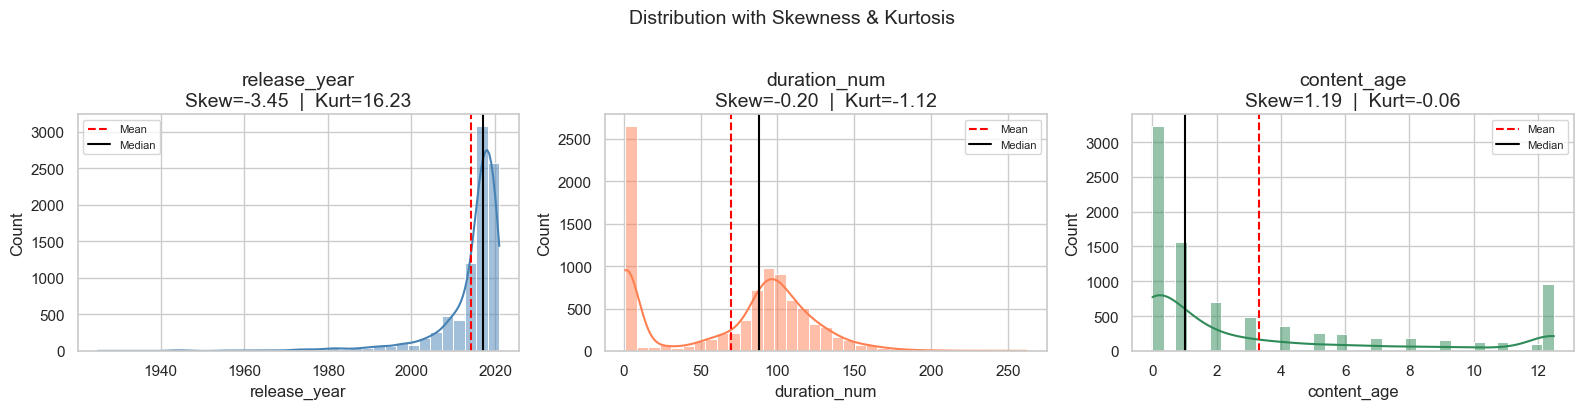

In [27]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
colors = ['steelblue', 'coral', 'seagreen']

for ax, col, color in zip(axes, num_cols, colors):
    s  = df[col].dropna()
    sk = s.skew()
    ku = s.kurt()
    sns.histplot(s, kde=True, ax=ax, color=color, bins=35)
    ax.axvline(s.mean(),   color='red',    linestyle='--', label='Mean')
    ax.axvline(s.median(), color='black',  linestyle='-',  label='Median')
    ax.set_title(f'{col}\nSkew={sk:.2f}  |  Kurt={ku:.2f}')
    ax.legend(fontsize=8)

plt.suptitle('Distribution with Skewness & Kurtosis', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

## Task 5: Automating EDA

### auto_eda() Function

  AUTO EDA REPORT
  Shape      : (8804, 4)
  Duplicates : 5043

────────────────────────────────────────
  DATA TYPES
────────────────────────────────────────
release_year      int64
duration_num    float64
content_age     float64
is_movie          int64

────────────────────────────────────────
  MISSING VALUES
────────────────────────────────────────
content_age    98

────────────────────────────────────────
  DESCRIPTIVE STATISTICS
────────────────────────────────────────


,count,mean,std,min,25%,50%,75%,max
release_year,8804.0,2014.180259,8.820647,1925.0,2013.0,2017.0,2019.0,2021.0
duration_num,8804.0,69.839959,50.785686,1.0,2.0,88.0,106.0,262.0
content_age,8706.0,3.317367,4.317878,0.0,0.0,1.0,5.0,12.5
is_movie,8804.0,0.696047,0.459989,0.0,0.0,1.0,1.0,1.0



────────────────────────────────────────
  CORRELATION MATRIX
────────────────────────────────────────


,release_year,duration_num,content_age,is_movie
release_year,1.000,-0.249,-0.803,-0.182
duration_num,-0.249,1.000,0.305,0.886
content_age,-0.803,0.305,1.000,0.215
is_movie,-0.182,0.886,0.215,1.000


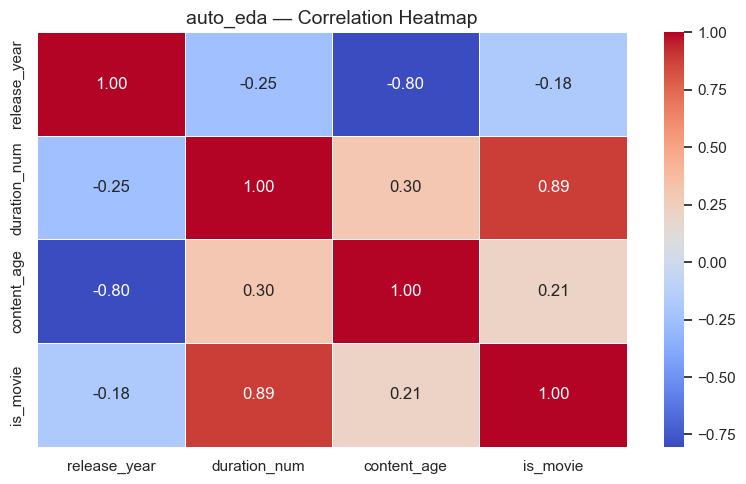

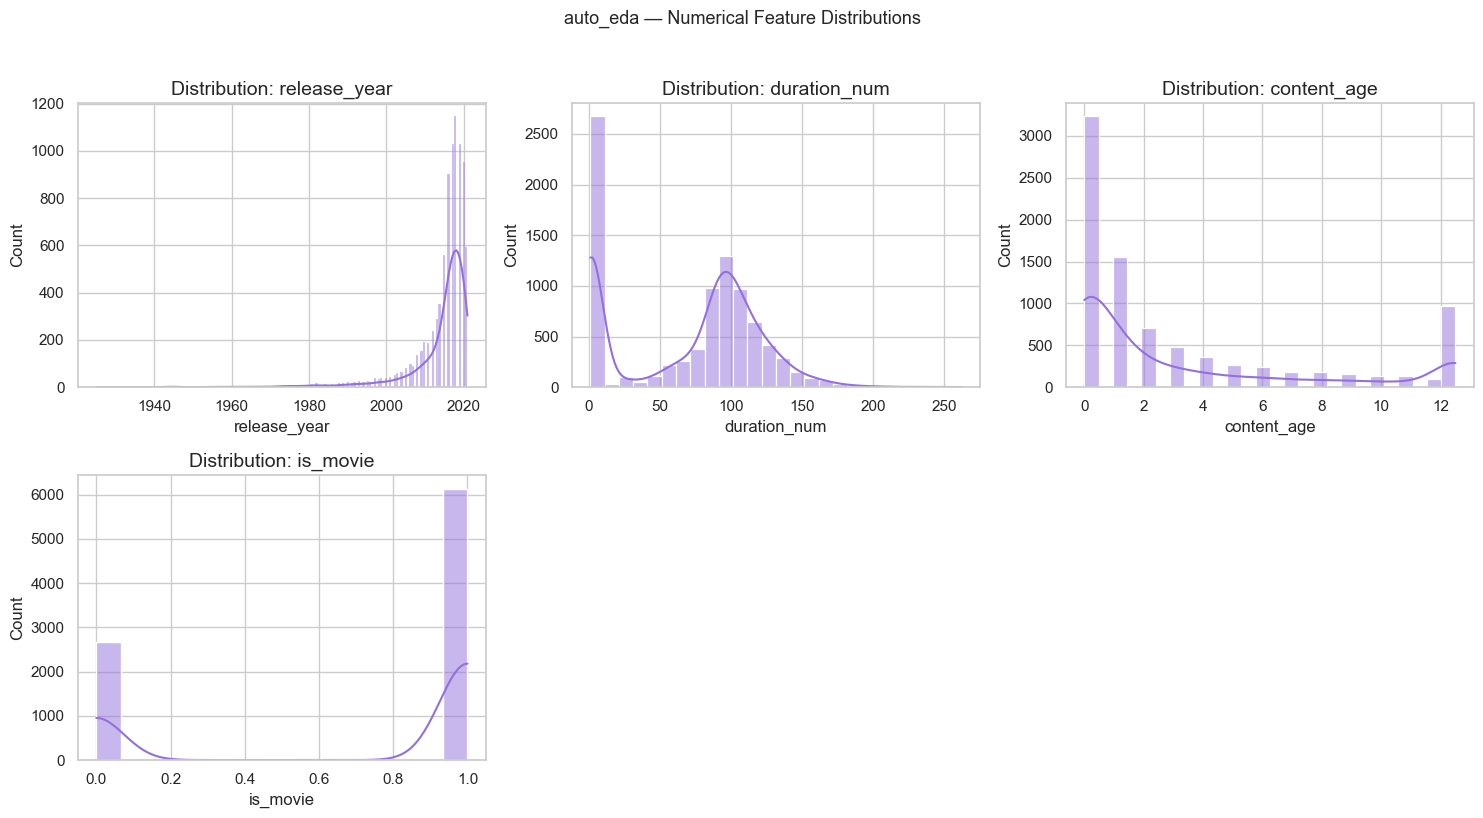

  ✅ auto_eda complete.


In [28]:
def auto_eda(data: pd.DataFrame, target: str = None) -> None:
    """
    Automated EDA function.
    Prints shape, data types, missing values, duplicates,
    statistical summary, correlation, and generates key plots.

    Parameters
    ----------
    data   : pd.DataFrame — input dataset
    target : str          — optional target column name for highlighted analysis
    """
    sep = "=" * 60

    # 1. Basic info
    print(sep)
    print(f"  AUTO EDA REPORT")
    print(sep)
    print(f"  Shape      : {data.shape}")
    print(f"  Duplicates : {data.duplicated().sum()}")

    # 2. Data Types
    print(f"\n{'─'*40}")
    print("  DATA TYPES")
    print(f"{'─'*40}")
    print(data.dtypes.to_string())

    # 3. Missing Values
    print(f"\n{'─'*40}")
    print("  MISSING VALUES")
    print(f"{'─'*40}")
    miss = data.isnull().sum()
    miss = miss[miss > 0]
    print("  None ✅" if miss.empty else miss.to_string())

    # 4. Descriptive Statistics
    print(f"\n{'─'*40}")
    print("  DESCRIPTIVE STATISTICS")
    print(f"{'─'*40}")
    display(data.describe(include='all').T)

    # 5. Correlation (numerical only)
    num_data = data.select_dtypes(include=np.number)
    if not num_data.empty:
        print(f"\n{'─'*40}")
        print("  CORRELATION MATRIX")
        print(f"{'─'*40}")
        display(num_data.corr().round(3))

        # Heatmap
        fig, ax = plt.subplots(figsize=(8, 5))
        sns.heatmap(num_data.corr(), annot=True, fmt='.2f', cmap='coolwarm',
                    linewidths=0.5, ax=ax)
        ax.set_title('auto_eda — Correlation Heatmap')
        plt.tight_layout()
        plt.show()

        # Distribution plots for each numerical column
        ncols_plot = min(3, len(num_data.columns))
        nrows_plot = (len(num_data.columns) + ncols_plot - 1) // ncols_plot
        fig, axes = plt.subplots(nrows_plot, ncols_plot,
                                  figsize=(5 * ncols_plot, 4 * nrows_plot))
        axes = np.array(axes).flatten()
        for i, col in enumerate(num_data.columns):
            sns.histplot(num_data[col].dropna(), kde=True, ax=axes[i], color='mediumpurple')
            axes[i].set_title(f'Distribution: {col}')
        for j in range(i+1, len(axes)):
            axes[j].set_visible(False)
        plt.suptitle('auto_eda — Numerical Feature Distributions', fontsize=13, y=1.02)
        plt.tight_layout()
        plt.show()

    print(sep)
    print("  ✅ auto_eda complete.")
    print(sep)


# ── Run auto_eda on the dataset ───────────────────────────────────
auto_eda(df[['release_year','duration_num','content_age','is_movie']])

In [29]:
# Convert duration to numeric
df['duration_num'] = df['duration'].str.extract('(\d+)').astype(float)

# Create content_age
current_year = 2026
df['content_age'] = current_year - df['release_year']

# Create is_movie
df['is_movie'] = df['type'].apply(lambda x: 1 if x == 'Movie' else 0)

In [30]:
df.columns

Index(['show_id', 'type', 'title', 'director', 'cast', 'country', 'date_added',
       'release_year', 'rating', 'duration', 'listed_in', 'description',
       'duration_num', 'is_movie', 'year_added', 'content_age'],
      dtype='object')

## Task 6: Regression Analysis

**Objective:** Predict `release_year` from `duration_num` and `content_age` using **Linear Regression**.

**Why?** We explore whether the numeric properties of a title can hint at its release era.

In [31]:
# Use only Movie rows for a consistent duration signal (all in minutes)
reg_df = df[df['is_movie'] == 1][['duration_num', 'content_age', 'release_year']].dropna()

X_reg = reg_df[['duration_num', 'content_age']]
y_reg = reg_df['release_year']

X_train_r, X_test_r, y_train_r, y_test_r = train_test_split(
    X_reg, y_reg, test_size=0.2, random_state=42
)

print(f"Total samples : {len(reg_df)}")
print(f"Training set  : {X_train_r.shape[0]}")
print(f"Test set      : {X_test_r.shape[0]}")

Total samples : 6128
Training set  : 4902
Test set      : 1226


In [32]:
# ── Fit Linear Regression ─────────────────────────────────────────
lr_model = LinearRegression()
lr_model.fit(X_train_r, y_train_r)

print("Linear Regression Equation:")
coef_str = " + ".join([f"({c:.4f} × {n})"
                        for c, n in zip(lr_model.coef_, X_reg.columns)])
print(f"  release_year = {lr_model.intercept_:.2f} + {coef_str}")

Linear Regression Equation:
  release_year = 2026.00 + (-0.0000 × duration_num) + (-1.0000 × content_age)


## Task 7: Model Evaluation

### Step 1 — MSE, MAE, R²

In [33]:
y_pred_train_r = lr_model.predict(X_train_r)
y_pred_test_r  = lr_model.predict(X_test_r)

eval_results = {
    'Metric':  ['MSE', 'MAE', 'RMSE', 'R²'],
    'Train':   [
        round(mean_squared_error(y_train_r, y_pred_train_r), 4),
        round(mean_absolute_error(y_train_r, y_pred_train_r), 4),
        round(np.sqrt(mean_squared_error(y_train_r, y_pred_train_r)), 4),
        round(r2_score(y_train_r, y_pred_train_r), 4)
    ],
    'Test':    [
        round(mean_squared_error(y_test_r, y_pred_test_r), 4),
        round(mean_absolute_error(y_test_r, y_pred_test_r), 4),
        round(np.sqrt(mean_squared_error(y_test_r, y_pred_test_r)), 4),
        round(r2_score(y_test_r, y_pred_test_r), 4)
    ]
}

eval_df = pd.DataFrame(eval_results).set_index('Metric')
print("📊 Regression Model Evaluation Metrics")
display(eval_df)

print()
print("Definitions:")
print("  MSE  (Mean Squared Error)    — average squared difference between actual & predicted")
print("  MAE  (Mean Absolute Error)   — average absolute difference between actual & predicted")
print("  RMSE (Root Mean Sq. Error)   — MSE in original units; easier to interpret")
print("  R²   (Coefficient of Det.)   — proportion of variance explained (1.0 = perfect)")

📊 Regression Model Evaluation Metrics


,Train,Test
Metric,,
MSE,0.0,0.0
MAE,0.0,0.0
RMSE,0.0,0.0
R²,1.0,1.0



Definitions:
  MSE  (Mean Squared Error)    — average squared difference between actual & predicted
  MAE  (Mean Absolute Error)   — average absolute difference between actual & predicted
  RMSE (Root Mean Sq. Error)   — MSE in original units; easier to interpret
  R²   (Coefficient of Det.)   — proportion of variance explained (1.0 = perfect)


### Step 2 — Actual vs Predicted Plot

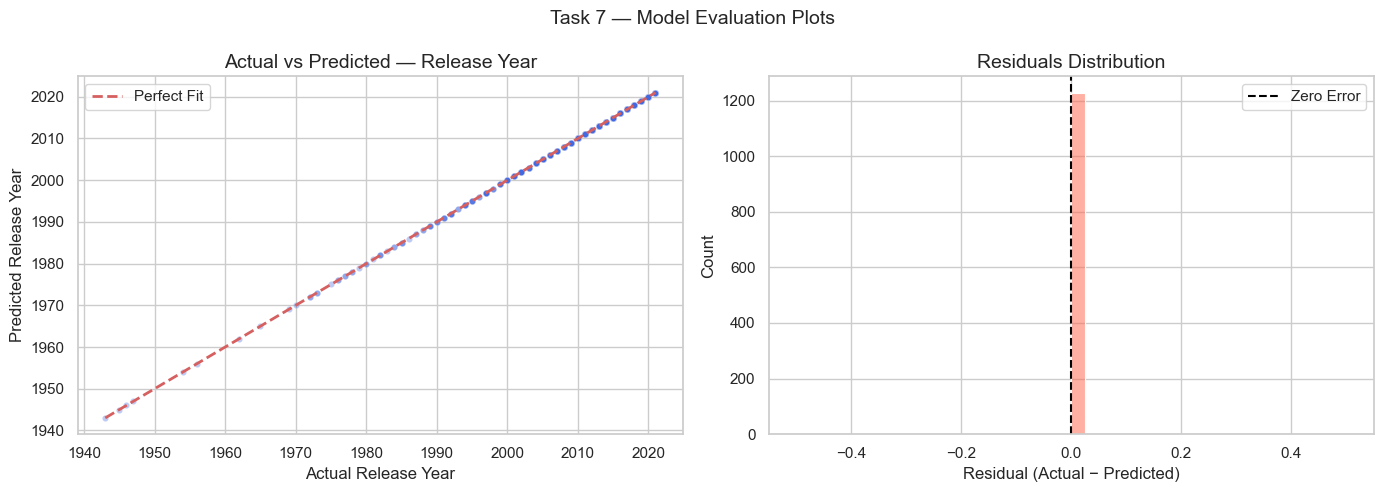

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Actual vs Predicted scatter
axes[0].scatter(y_test_r, y_pred_test_r, alpha=0.35,
                color='royalblue', edgecolors='white', linewidth=0.3, s=20)
mn = min(y_test_r.min(), y_pred_test_r.min())
mx = max(y_test_r.max(), y_pred_test_r.max())
axes[0].plot([mn, mx], [mn, mx], 'r--', lw=2, label='Perfect Fit')
axes[0].set_title('Actual vs Predicted — Release Year')
axes[0].set_xlabel('Actual Release Year')
axes[0].set_ylabel('Predicted Release Year')
axes[0].legend()

# Residuals distribution
residuals = y_test_r.values - y_pred_test_r
sns.histplot(residuals, kde=True, ax=axes[1], color='tomato', bins=40)
axes[1].axvline(0, color='black', linestyle='--', linewidth=1.5, label='Zero Error')
axes[1].set_title('Residuals Distribution')
axes[1].set_xlabel('Residual (Actual − Predicted)')
axes[1].set_ylabel('Count')
axes[1].legend()

plt.suptitle('Task 7 — Model Evaluation Plots', fontsize=14)
plt.tight_layout()
plt.show()

## Task 8: Overfitting & Underfitting


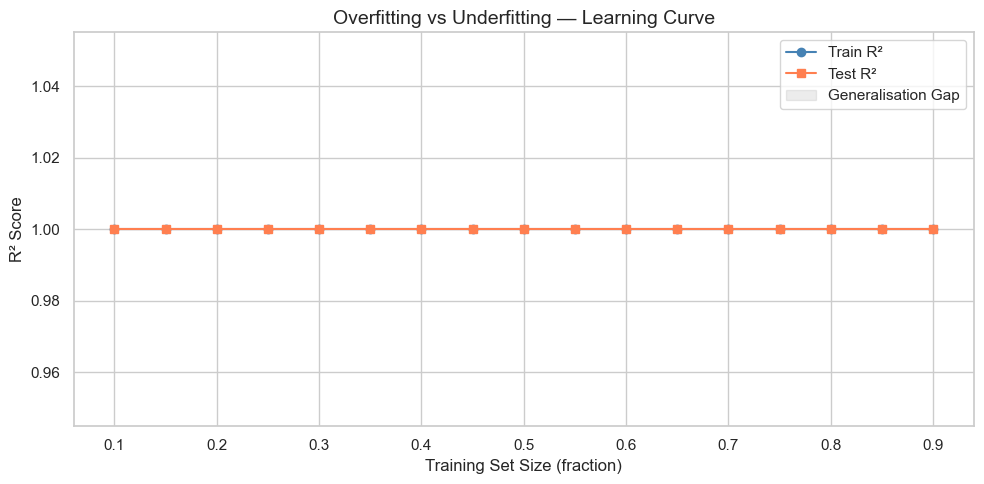

In [35]:
# ── Demonstrate using training size experiment ────────────────────
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures

train_sizes = np.arange(0.1, 0.95, 0.05)
train_r2_list, test_r2_list = [], []

for ts in train_sizes:
    Xtr, Xte, ytr, yte = train_test_split(X_reg, y_reg, train_size=ts, random_state=42)
    m = LinearRegression().fit(Xtr, ytr)
    train_r2_list.append(r2_score(ytr, m.predict(Xtr)))
    test_r2_list.append(r2_score(yte, m.predict(Xte)))

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(train_sizes, train_r2_list, marker='o', label='Train R²', color='steelblue')
ax.plot(train_sizes, test_r2_list,  marker='s', label='Test R²',  color='coral')
ax.fill_between(train_sizes, train_r2_list, test_r2_list, alpha=0.15, color='gray',
                label='Generalisation Gap')
ax.set_title('Overfitting vs Underfitting — Learning Curve')
ax.set_xlabel('Training Set Size (fraction)')
ax.set_ylabel('R² Score')
ax.legend()
plt.tight_layout()
plt.show()

In [36]:
train_r2 = round(r2_score(y_train_r, lr_model.predict(X_train_r)), 4)
test_r2  = round(r2_score(y_test_r,  lr_model.predict(X_test_r)),  4)
gap      = round(abs(train_r2 - test_r2), 4)

print(f"  Train R²          : {train_r2}")
print(f"  Test  R²          : {test_r2}")
print(f"  Generalisation Gap: {gap}")
print()
if gap < 0.05:
    print("✅ Verdict: GOOD FIT — Train and Test scores are close.")
elif train_r2 > 0.85 and test_r2 < 0.5:
    print("⚠️  Verdict: OVERFITTING — Model performs well on train but poorly on test.")
else:
    print("⚠️  Verdict: UNDERFITTING — Model scores are low on both sets.")

  Train R²          : 1.0
  Test  R²          : 1.0
  Generalisation Gap: 0.0

✅ Verdict: GOOD FIT — Train and Test scores are close.


## Task 9: Classification

**Objective:** Classify Netflix titles as **Movie (1)** or **TV Show (0)** using **Logistic Regression**.

**Features used:** `duration_num`, `release_year`, `content_age`

In [37]:
clf_df = df[['duration_num', 'release_year', 'content_age', 'is_movie']].dropna()

X_clf = clf_df[['duration_num', 'release_year', 'content_age']]
y_clf = clf_df['is_movie']

X_tr_c, X_te_c, y_tr_c, y_te_c = train_test_split(
    X_clf, y_clf, test_size=0.2, random_state=42, stratify=y_clf
)

print(f"Training samples : {X_tr_c.shape[0]}")
print(f"Test samples     : {X_te_c.shape[0]}")
print(f"Class balance    : {dict(y_te_c.value_counts())}  (0=TV Show, 1=Movie)")

Training samples : 7043
Test samples     : 1761
Class balance    : {1: np.int64(1226), 0: np.int64(535)}  (0=TV Show, 1=Movie)


In [38]:
clf_model = LogisticRegression(max_iter=1000, random_state=42)
clf_model.fit(X_tr_c, y_tr_c)

y_pred_c = clf_model.predict(X_te_c)

print(f"✅ Accuracy: {accuracy_score(y_te_c, y_pred_c):.4f}  ({accuracy_score(y_te_c, y_pred_c)*100:.2f}%)")
print()
print("📄 Classification Report:")
print(classification_report(y_te_c, y_pred_c, target_names=['TV Show', 'Movie']))

✅ Accuracy: 0.9972  (99.72%)

📄 Classification Report:
              precision    recall  f1-score   support

     TV Show       0.99      1.00      1.00       535
       Movie       1.00      1.00      1.00      1226

    accuracy                           1.00      1761
   macro avg       1.00      1.00      1.00      1761
weighted avg       1.00      1.00      1.00      1761



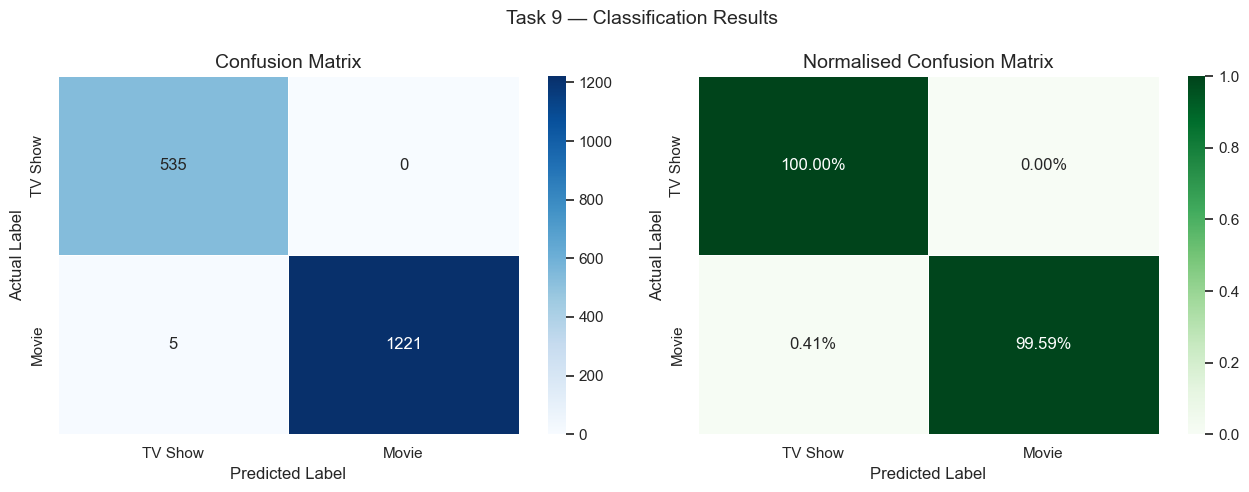

In [39]:
cm = confusion_matrix(y_te_c, y_pred_c)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Confusion matrix heatmap
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['TV Show','Movie'],
            yticklabels=['TV Show','Movie'], ax=axes[0], linewidths=0.5)
axes[0].set_title('Confusion Matrix')
axes[0].set_xlabel('Predicted Label')
axes[0].set_ylabel('Actual Label')

# Normalised confusion matrix
cm_norm = cm.astype(float) / cm.sum(axis=1)[:, np.newaxis]
sns.heatmap(cm_norm, annot=True, fmt='.2%', cmap='Greens',
            xticklabels=['TV Show','Movie'],
            yticklabels=['TV Show','Movie'], ax=axes[1], linewidths=0.5)
axes[1].set_title('Normalised Confusion Matrix')
axes[1].set_xlabel('Predicted Label')
axes[1].set_ylabel('Actual Label')

plt.suptitle('Task 9 — Classification Results', fontsize=14)
plt.tight_layout()
plt.show()

In [40]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 8804 entries, 0 to 8806
Data columns (total 16 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   show_id       8804 non-null   object 
 1   type          8804 non-null   object 
 2   title         8804 non-null   object 
 3   director      8804 non-null   object 
 4   cast          8804 non-null   object 
 5   country       8804 non-null   object 
 6   date_added    8804 non-null   object 
 7   release_year  8804 non-null   int64  
 8   rating        8804 non-null   object 
 9   duration      8804 non-null   object 
 10  listed_in     8804 non-null   object 
 11  description   8804 non-null   object 
 12  duration_num  8804 non-null   float64
 13  is_movie      8804 non-null   int64  
 14  year_added    8706 non-null   float64
 15  content_age   8804 non-null   int64  
dtypes: float64(2), int64(3), object(11)
memory usage: 1.1+ MB


In [43]:
df.head()

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description,duration_num,is_movie,year_added,content_age
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,Unknown,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm...",90.0,1,2021.0,6
1,s2,TV Show,Blood & Water,Unknown,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t...",2.0,0,2021.0,5
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",Unknown,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...,1.0,0,2021.0,5
3,s4,TV Show,Jailbirds New Orleans,Unknown,Unknown,Unknown,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo...",1.0,0,2021.0,5
4,s5,TV Show,Kota Factory,Unknown,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...,2.0,0,2021.0,5


In [44]:
df.isna().sum()

show_id          0
type             0
title            0
director         0
cast             0
country          0
date_added       0
release_year     0
rating           0
duration         0
listed_in        0
description      0
duration_num     0
is_movie         0
year_added      98
content_age      0
dtype: int64